in this cell you loop on the bbc folder to collect the folder names and put it as labels then you enter each folder and check if it's a text file you will read it and put it in list named row, after you read all of them you will put the list in dataframe 

In [1]:
import os, pandas as pd

root = "dataset/bbc"
rows = []
for label in sorted(os.listdir(root)):
    folder = os.path.join(root, label)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        path = os.path.join(folder, fname)
        if not fname.endswith(".txt"):
            continue
        with open(path, encoding="latin-1") as f:
            rows.append({"text": f.read().strip(), "label": label})

df = pd.DataFrame(rows)

In [2]:
print (df)
print ("number of rows ", len(df) )
print("Class labels:", sorted(df["label"].unique()))
print(df["label"].value_counts())

                                                   text     label
0     Ad sales boost Time Warner profit\n\nQuarterly...  business
1     Dollar gains on Greenspan speech\n\nThe dollar...  business
2     Yukos unit buyer faces loan claim\n\nThe owner...  business
3     High fuel prices hit BA's profits\n\nBritish A...  business
4     Pernod takeover talk lifts Domecq\n\nShares in...  business
...                                                 ...       ...
2220  BT program to beat dialler scams\n\nBT is intr...      tech
2221  Spam e-mails tempt net shoppers\n\nComputer us...      tech
2222  Be careful how you code\n\nA new European dire...      tech
2223  US cyber security chief resigns\n\nThe man mak...      tech
2224  Losing yourself in online gaming\n\nOnline rol...      tech

[2225 rows x 2 columns]
number of rows  2225
Class labels: ['business', 'entertainment', 'politics', 'sport', 'tech']
label
sport            511
business         510
politics         417
tech             401

In [3]:
print (df.isna().sum())

text     0
label    0
dtype: int64


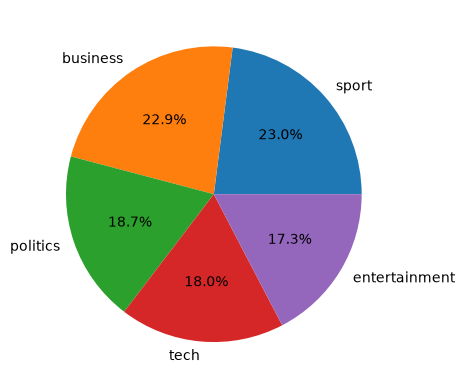

In [8]:
import matplotlib.pyplot as plt
from collections import Counter
df["label"].value_counts().plot(kind="pie" , autopct="%1.1f%%")
plt.show()

In [6]:
df["wCount"] = df["text"].str.split().str.len()
print (df)
print (df["wCount"].describe())

                                                   text     label  wCount
0     Ad sales boost Time Warner profit\n\nQuarterly...  business     421
1     Dollar gains on Greenspan speech\n\nThe dollar...  business     384
2     Yukos unit buyer faces loan claim\n\nThe owner...  business     264
3     High fuel prices hit BA's profits\n\nBritish A...  business     406
4     Pernod takeover talk lifts Domecq\n\nShares in...  business     265
...                                                 ...       ...     ...
2220  BT program to beat dialler scams\n\nBT is intr...      tech     420
2221  Spam e-mails tempt net shoppers\n\nComputer us...      tech     357
2222  Be careful how you code\n\nA new European dire...      tech    1050
2223  US cyber security chief resigns\n\nThe man mak...      tech     379
2224  Losing yourself in online gaming\n\nOnline rol...      tech    2969

[2225 rows x 3 columns]
count    2225.000000
mean      384.040449
std       238.174497
min        89.000000
25%